# Texte biologique COHERENT (prose fluide, pas une liste)

Meme espece que `test_long_text.ipynb`, mais reecrit comme une **vraie description biologique** : les phrases
s'enchainent (« so that… », « after which… », « whereas… », « which represents 38 % of… »), avec des points-virgules,
des incises et des comparaisons entre traits — au lieu d'une simple enumeration de mesures.

Resultat teste : **le modele extrait quand meme tous les traits**.

## Ce qui preserve l'extraction malgre la fluidite
| Fonctionne | Exemple |
|---|---|
| connecteurs en tete de phrase | « **Under the same thermal regime**, the time since birth at weaning is… » |
| propositions relatives apres le trait | « …the total length at puberty is 8.2 cm, **which represents roughly 38 %** of… » |
| point-virgule liant deux idees | « …lasts approximately 12 days**;** this brief embryonic phase… » |
| comparaison entre deux traits | « 8.2 cm … **of the ultimate total length of** 21.5 cm » |
| participiales apres le trait | « …**having by then attained** a wet weight at weaning of 3.4 grams » |

| A eviter | Pourquoi |
|---|---|
| mettre le trait dans une **subordonnee d'ouverture** | « *Taken together with the maximum documented life span of 8 years*, ces figures… » -> **rate** |
| vocabulaire grand public | « newborn kits weigh 45 g » -> **rate** (le modele attend « wet weight at birth ») |

In [1]:
import html as _html
import re
from pathlib import Path

import pandas as pd
import torch
from IPython.display import HTML, display
from transformers import AutoModelForTokenClassification, AutoTokenizer

ROOT = Path.cwd()
while not (ROOT / "outputs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
MODEL_DIR = ROOT / "outputs" / "bio" / "bert" / "baseline" / "final_model"

device = "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR), add_prefix_space=True)
model = AutoModelForTokenClassification.from_pretrained(str(MODEL_DIR)).eval().to(device)
id2label = {int(k): v for k, v in model.config.id2label.items()}
MAX_LEN = min(tokenizer.model_max_length, model.config.max_position_embeddings)

_SENT = re.compile(r"(?<=[.!?])\s+")
_WORD = re.compile(r"\d+(?:[.,]\d+)*|\w+|[^\w\s]")


def _spans(tags, offsets):
    spans, cur = [], None
    for tag, (start, end) in zip(tags, offsets):
        if tag == "O":
            if cur: spans.append(cur); cur = None
            continue
        prefix, etype = tag.split("-", 1)
        if prefix == "B":
            if cur: spans.append(cur)
            cur = {"type": etype, "start": start, "end": end}
        elif cur and cur["type"] == etype:
            cur["end"] = end
    if cur: spans.append(cur)
    return spans


def analyse(text):
    out = []
    for sentence in [s for s in _SENT.split(text.strip()) if s]:
        pairs = [(m.group(), (m.start(), m.end())) for m in _WORD.finditer(sentence)]
        if not pairs:
            out.append((sentence, [])); continue
        words, offsets = zip(*pairs)
        enc = tokenizer(list(words), is_split_into_words=True, return_tensors="pt",
                        truncation=True, max_length=MAX_LEN)
        word_ids = enc.word_ids(batch_index=0)
        enc = {k: v.to(device) for k, v in enc.items()}
        with torch.no_grad():
            pred = model(**enc).logits[0].argmax(-1).tolist()
        seen, tags, offs = set(), [], []
        for i, w in enumerate(word_ids):
            if w is None or w in seen: continue
            seen.add(w); tags.append(id2label[pred[i]]); offs.append(offsets[w])
        out.append((sentence, _spans(tags, offs)))
    return out


def table(text):
    return pd.DataFrame([{"Type": sp["type"], "Texte extrait": sent[sp["start"]:sp["end"]]}
                         for sent, spans in analyse(text) for sp in spans])


_PALETTE = ["#c6dbef", "#c7e9c0", "#fdd0a2", "#dadaeb", "#fdd49e", "#d9f0d3",
            "#fde0dd", "#e5f5e0", "#bcbddc", "#fdae6b", "#a1d99b", "#9ecae1"]


def highlight(text):
    colors, blocks = {}, []
    for sent, spans in analyse(text):
        pieces, last = [], 0
        for sp in sorted(spans, key=lambda s: s["start"]):
            if sp["start"] < last: continue
            col = colors.setdefault(sp["type"], _PALETTE[len(colors) % len(_PALETTE)])
            pieces.append(_html.escape(sent[last:sp["start"]]))
            pieces.append(
                f'<mark style="background:{col};color:#111;padding:1px 4px;border-radius:4px">'
                f'{_html.escape(sent[sp["start"]:sp["end"]])}'
                f' <span style="opacity:.6;font-size:.88em;font-weight:500">({sp["type"]})</span></mark>')
            last = sp["end"]
        pieces.append(_html.escape(sent[last:]))
        blocks.append("".join(pieces))
    return HTML("<div style='line-height:2.1;font-size:15px'>" + " ".join(blocks) + "</div>")

print("Modele charge |", device, "|", len(id2label), "labels")

Modele charge | mps | 41 labels


### Le texte coherent

In [2]:
COHERENT_TEXT = (
    "The freshwater cyprinid Rutilus meridionalis is widely distributed throughout the slow-flowing lowland "
    "rivers of southern Europe, where its entire life history is tuned to a moderately warm thermal regime. "
    "At a stable water temperature of 17 \u00b0C, the period from fertilisation to hatching, i.e. "
    "the age at birth, lasts approximately 12 days; "
    "this comparatively brief embryonic phase is made possible by the substantial maternal provisioning evident "
    "in the eggs, whose initial wet weight has been recorded at 0.85 grams. "
    "Upon eclosion the prolarvae remain poorly developed, possessing a total length at birth of only 0.6 cm and "
    "a wet weight at birth of approximately 1.2 grams, so that the first weeks of life are dominated by rapid "
    "somatic growth rather than by foraging. "
    "Under the same thermal regime the time since birth at weaning is approximately 21 days since birth, after "
    "which the young exhaust their yolk reserves and begin to feed exogenously, having by then attained a wet "
    "weight at weaning of 3.4 grams. "
    "Growth slows markedly thereafter, as energy is progressively diverted from somatic maintenance towards "
    "reproduction. "
    "Scale annuli and length-frequency histograms indicate that the total length at puberty is 8.2 cm, which "
    "represents roughly 38 % of the ultimate total length of 21.5 cm and is consistent with an early-maturing "
    "life cycle; "
    "at that stage females exhibit a wet weight at puberty of 24 grams. "
    "Females typically attain puberty at approximately 730 days after hatching, whereas the time since birth at "
    "first brood for breeding females is approximately 950 days, the delay reflecting the additional energy "
    "required to complete a first clutch. "
    "Once fully grown, adults reach an ultimate wet weight of 145 grams, and a female of this size can produce "
    "approximately 320 eggs per day throughout the spawning season. "
    "This considerable reproductive investment is mirrored in the gonads, since at death the gonadosomatic "
    "index (GSI) was recorded at 18 % at a temperature of 17 \u00b0C. "
    "Longevity records obtained from mark-recapture studies indicate that the maximum documented life span of "
    "this species is 8 years, which, combined with the high reproductive output described above, characterises "
    "a fast life cycle typical of temperate cyprinids. "
).strip()

df = table(COHERENT_TEXT)
print(f"{len(df)} entites extraites  |  {df['Type'].nunique()} types de traits")
display(df)

17 entites extraites  |  16 types de traits


,Type,Texte extrait
0,T,17 °C
1,ab,approximately 12 days
2,Ww0,0.85 grams
3,Lb,0.6 cm
4,Wwb,approximately 1.2 grams
5,tx,approximately 21 days since birth
6,Wwx,3.4 grams
7,Lp,8.2 cm
8,Li,21.5 cm
9,Wwp,24 grams


### Export : 2 images PNG a FOND BLANC (pour la these)

1. **`texte_brut.png`** — le texte seul, sans annotation (avant application du modele)
2. **`texte_annote.png`** — le meme texte annote par le modele (entites surlignees + type en exposant)

Enregistrees dans `analysis/figures/`.

enregistre -> /Users/somaya/Documents/Phd/github_version/version_3/animalia-Github/animalia-dataset_pipeline/data_in_brief_server/analysis/figures/texte_brut.png
enregistre -> /Users/somaya/Documents/Phd/github_version/version_3/animalia-Github/animalia-dataset_pipeline/data_in_brief_server/analysis/figures/texte_annote.png


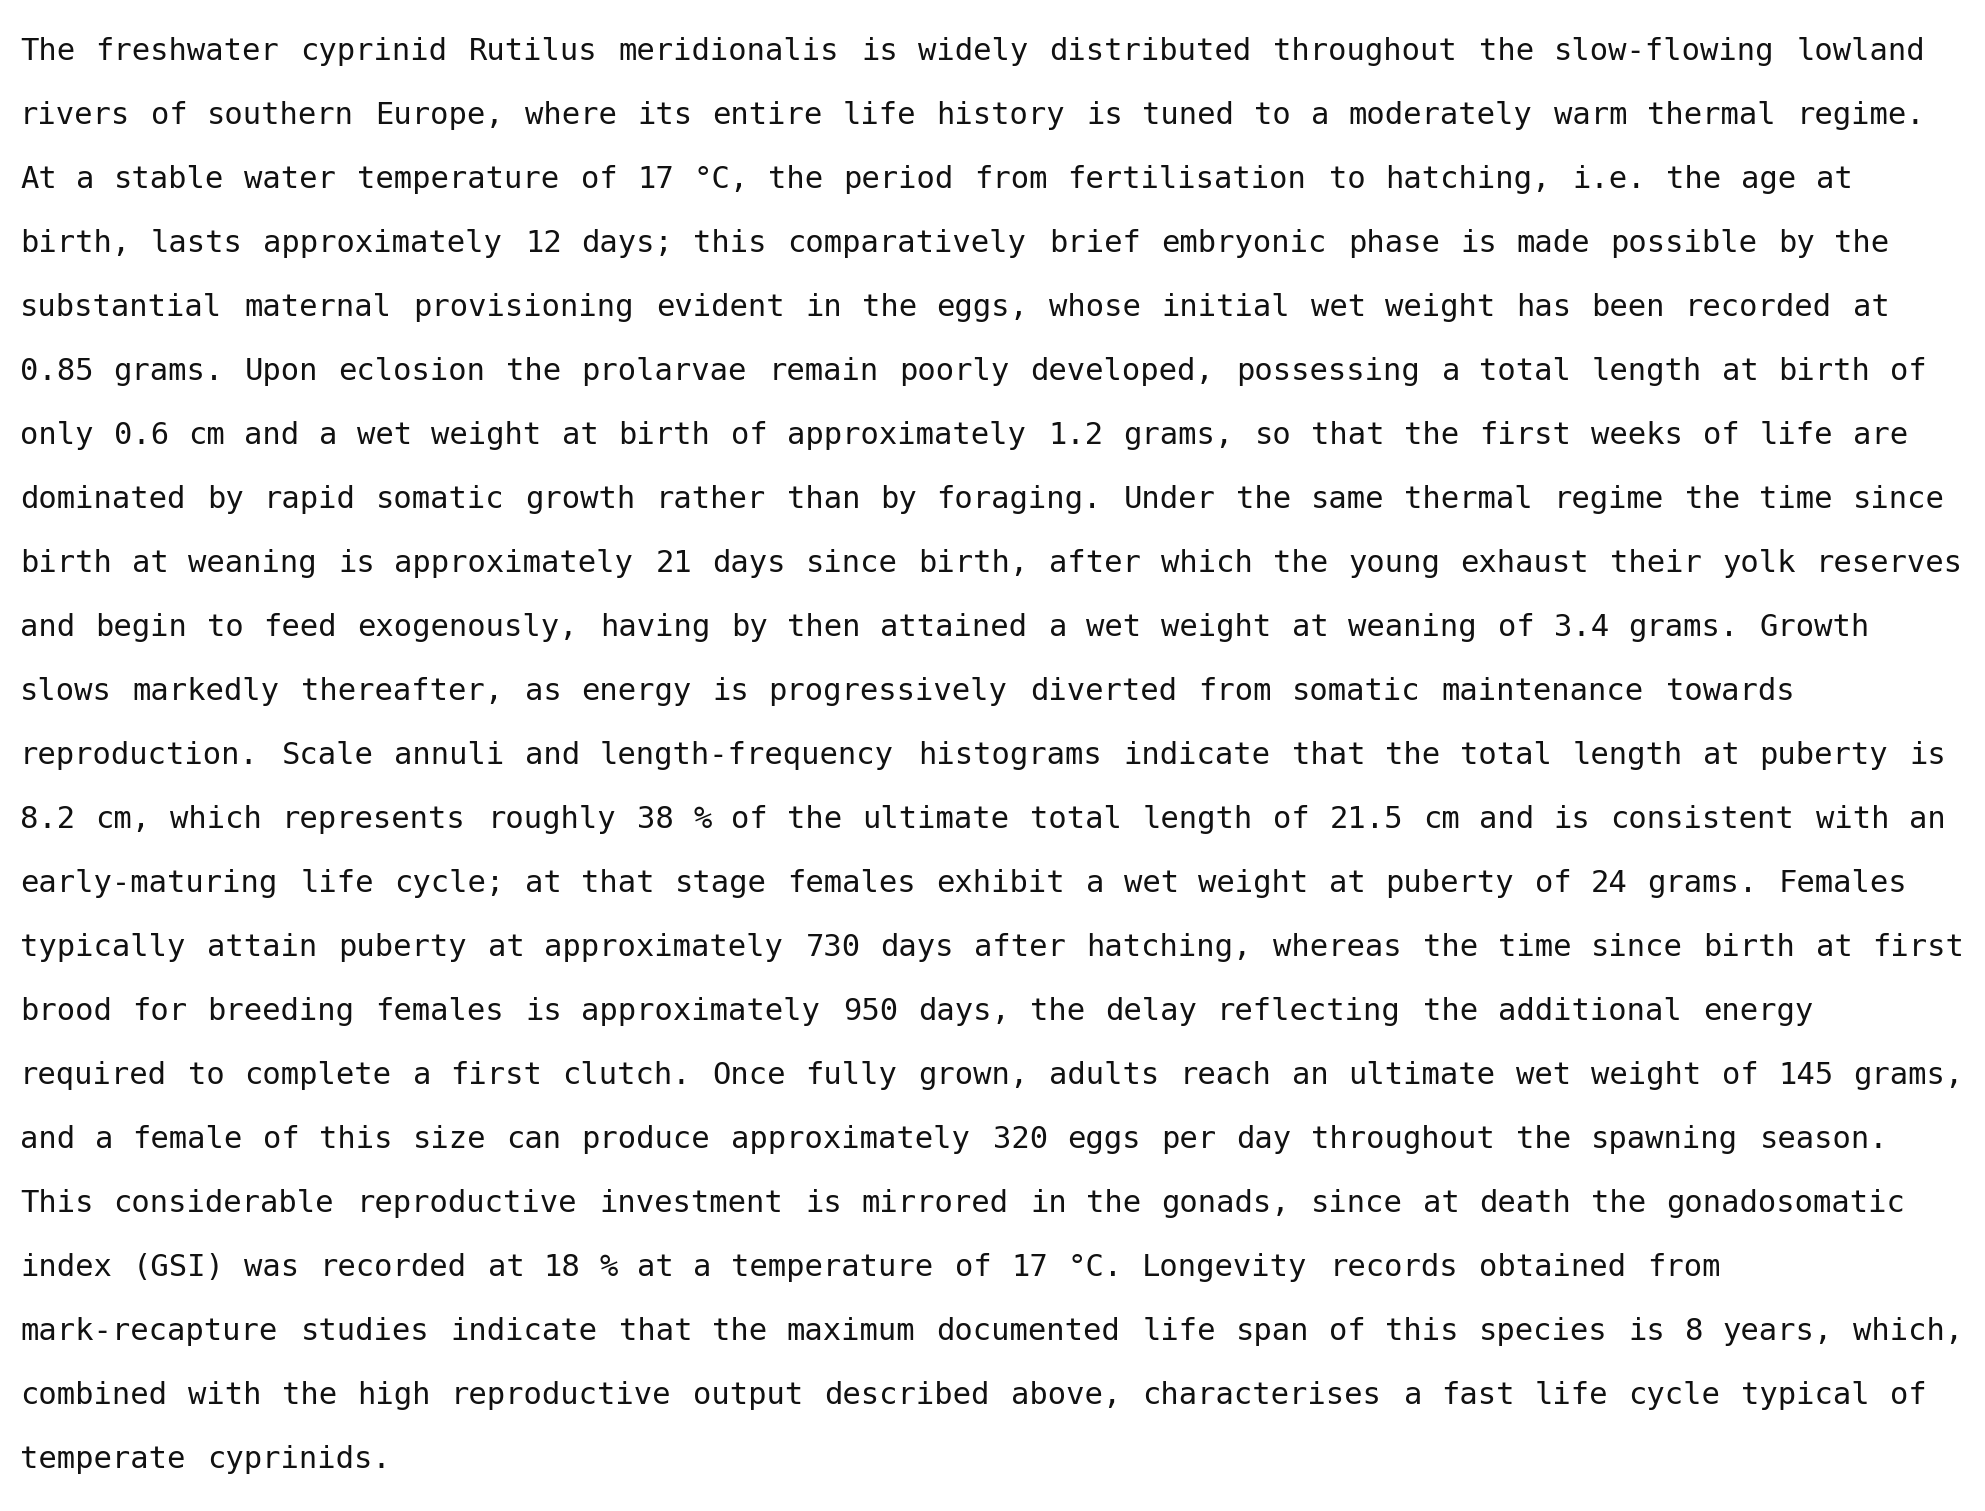

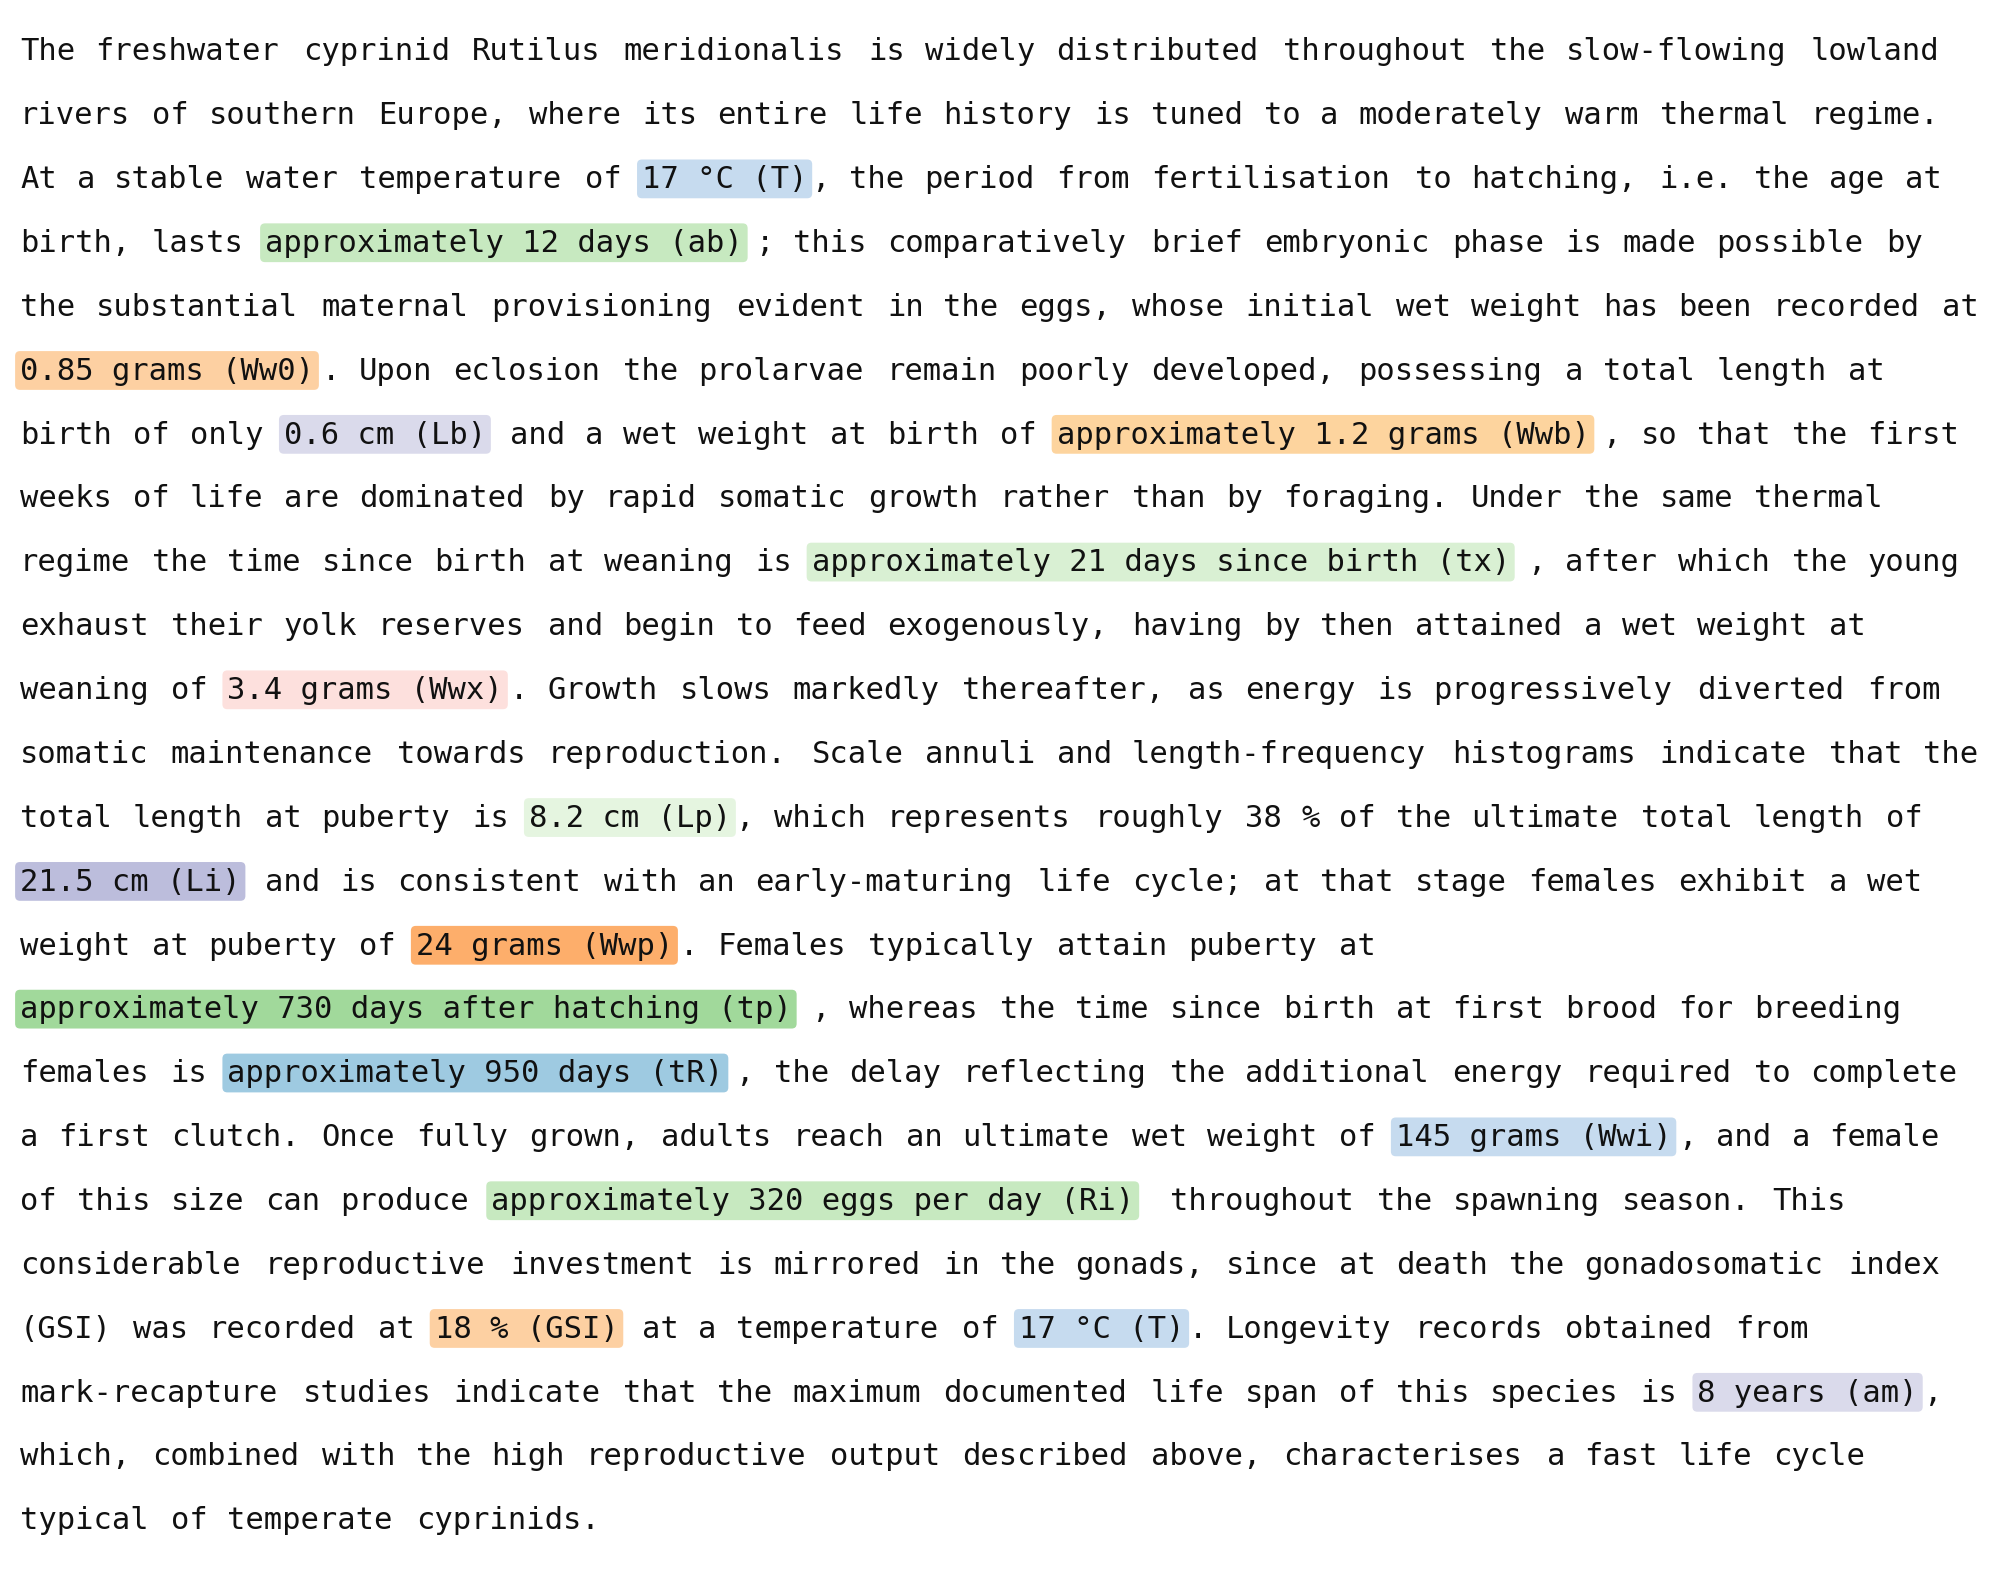

In [3]:
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage

FIG_DIR = ROOT / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
_PUNCT = set(",.;:!?)")


def _img_tokens(text, annotate):
    """Decoupe le texte en jetons ; chaque entite reste ATOMIQUE (une seule boite)."""
    if not annotate:
        return [(w, None) for w in text.split()]
    toks = []
    for sent, spans in analyse(text):
        last = 0
        for sp in sorted(spans, key=lambda s: s["start"]):
            if sp["start"] < last:
                continue
            toks += [(w, None) for w in sent[last:sp["start"]].split()]
            toks.append((sent[sp["start"]:sp["end"]], sp["type"]))
            last = sp["end"]
        toks += [(w, None) for w in sent[last:].split()]
    return toks


def render_image(text, annotate, out_path, chars_per_line=104, fontsize=11):
    """PNG fond blanc. Le type d'entite est ecrit ENTRE PARENTHESES, dans la boite coloree."""
    def lead(t, e, first):
        return 0 if (first or (e is None and t and all(ch in _PUNCT for ch in t))) else 1

    def label(t, e):
        return f"{t} ({e})" if e else t

    toks, colors = _img_tokens(text, annotate), {}
    lines, cur, w = [], [], 0
    for t, e in toks:
        L = lead(t, e, not cur)
        tw = L + len(label(t, e))
        if w + tw > chars_per_line and cur:
            lines.append(cur); cur, w = [], 0
            L = lead(t, e, True); tw = L + len(label(t, e))
        cur.append((t, e, L)); w += tw
    if cur:
        lines.append(cur)

    CW, LH = 0.6 * fontsize / 72, 2.0 * fontsize / 72
    fig, ax = plt.subplots(figsize=(chars_per_line * CW + 0.4, len(lines) * LH + 0.4))
    fig.patch.set_facecolor("white"); ax.set_facecolor("white")
    ax.set_xlim(0, chars_per_line); ax.set_ylim(len(lines), 0); ax.axis("off")

    for li, line in enumerate(lines):
        col = 0
        for t, e, L in line:
            col += L
            txt = label(t, e)
            if e:
                colors.setdefault(e, _PALETTE[len(colors) % len(_PALETTE)])
                ax.text(col, li + 0.5, txt, family="monospace", fontsize=fontsize,
                        va="center", ha="left", color="#111",
                        bbox=dict(facecolor=colors[e], edgecolor="none", boxstyle="round,pad=0.16"))
            else:
                ax.text(col, li + 0.5, txt, family="monospace", fontsize=fontsize,
                        va="center", ha="left", color="#111")
            col += len(txt)

    fig.tight_layout(pad=0.25)
    fig.savefig(out_path, dpi=200, facecolor="white", bbox_inches="tight")
    plt.close(fig)
    print("enregistre ->", out_path)


render_image(COHERENT_TEXT, annotate=False, out_path=FIG_DIR / "texte_brut.png")
render_image(COHERENT_TEXT, annotate=True,  out_path=FIG_DIR / "texte_annote.png")

display(IPImage(str(FIG_DIR / "texte_brut.png")))
display(IPImage(str(FIG_DIR / "texte_annote.png")))

### Le texte brut (avant annotation)

Le texte tel quel, sans passer par le modele — affiche dans la sortie (pas une image).

In [4]:
display(HTML(
    "<div style='line-height:2;font-size:15px'>"
    + _html.escape(COHERENT_TEXT)
    + "</div>"
))

### Le texte surligne

In [5]:
highlight(COHERENT_TEXT)

### Recapitulatif

In [6]:
counts = df["Type"].value_counts().rename_axis("Trait").reset_index(name="Occurrences")
display(counts)
print("Traits detectes :", ", ".join(sorted(df["Type"].unique())))

,Trait,Occurrences
0,T,2
1,ab,1
2,Ww0,1
3,Lb,1
4,Wwb,1
5,tx,1
6,Wwx,1
7,Lp,1
8,Li,1
9,Wwp,1


Traits detectes : GSI, Lb, Li, Lp, Ri, T, Ww0, Wwb, Wwi, Wwp, Wwx, ab, am, tR, tp, tx


### A toi : ecris ta propre prose

Garde la fluidite, mais **nomme explicitement le trait** et place-le dans la **proposition principale**
(pas dans une subordonnee d'ouverture).

In [7]:
MY_TEXT = (
    "In this population the reproductive cycle is closely tied to temperature: at a stable water temperature "
    "of 20 °C, the age at birth was recorded as 9 days, a value that reflects rapid embryonic development. "
    "Newly hatched larvae possess a wet weight at birth of approximately 0.4 grams, and growth is rapid "
    "thereafter, so that the species attains a maximum recorded total length of 14.2 cm. The ultimate wet "
    "weight of fully grown adults has been estimated at 62 grams, whereas the maximum documented life span "
    "of this species is 6 years."
)

my_df = table(MY_TEXT)
print(f"{len(my_df)} entites extraites")
display(my_df)
display(highlight(MY_TEXT))

6 entites extraites


,Type,Texte extrait
0,T,20 °C
1,ab,9 days
2,Wwb,approximately 0.4 grams
3,Li,14.2 cm
4,Wwi,62 grams
5,am,6 years
